# 05 — Final 3-protein model and subgroup analysis

Final model:

- `NPX_GDF15`
- `NPX_SFTPB`
- `NPX_WFDC2`

The prediction model itself uses **only these three proteins**.

Age, cigarette pack-years and sex are **not added as predictors** in this notebook. Instead, after the model makes predictions, they are used to examine whether sensitivity and specificity change across participant subgroups.

These analyses are exploratory robustness checks, not external clinical validation.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy.stats import linregress
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

TRAIN_FILENAME = "TrainData.csv"
TEST_FILENAME = "TestData.csv"
TARGET = "clinic_group"

MODEL_PROTEINS = ["NPX_GDF15", "NPX_SFTPB", "NPX_WFDC2"]
HEALTHY_GROUPS = {"Healthy_control", "Non_stable_fibrotic_ILA"}
UNHEALTHY_GROUPS = {"Stable_fibrotic_ILA", "Progressive_ILA", "Established_ILD"}

RANDOM_STATE = 42
N_INTERVALS = 8
N_BOOTSTRAP = 2000

def resolve_data_file(filename):
    for path in [Path("data") / filename, Path(filename)]:
        if path.exists():
            return path
    raise FileNotFoundError(
        f"Could not find {filename}. Put the authorized file in ./data/ "
        "or next to this notebook. Do not commit it to GitHub."
    )

train = pd.read_csv(resolve_data_file(TRAIN_FILENAME))
test = pd.read_csv(resolve_data_file(TEST_FILENAME))
train.columns = train.columns.astype(str).str.strip()
test.columns = test.columns.astype(str).str.strip()

required = [TARGET, "age", "cigarette_packs_year", "sex"] + MODEL_PROTEINS

for name, data in [("train", train), ("test", test)]:
    missing = [c for c in required if c not in data.columns]
    if missing:
        raise ValueError(f"Missing columns in {name}: {missing}")

for col in ["age", "cigarette_packs_year"]:
    train[col] = pd.to_numeric(train[col], errors="coerce")
    test[col] = pd.to_numeric(test[col], errors="coerce")

train["sex"] = train["sex"].astype("string").str.strip()
test["sex"] = test["sex"].astype("string").str.strip()

mapping = {
    **{g: 0 for g in HEALTHY_GROUPS},
    **{g: 1 for g in UNHEALTHY_GROUPS},
}

y_train = train[TARGET].astype(str).map(mapping).to_numpy()
y_test = test[TARGET].astype(str).map(mapping).to_numpy()

if np.isnan(y_train).any() or np.isnan(y_test).any():
    raise ValueError("Unexpected clinic_group value found.")


In [2]:
X_train = train[MODEL_PROTEINS].apply(pd.to_numeric, errors="coerce")
X_test = test[MODEL_PROTEINS].apply(pd.to_numeric, errors="coerce")

model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=-6)),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=4000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])

model.fit(X_train, y_train)
pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]

tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
fpr, tpr, _ = roc_curve(y_test, prob)

OverallPerformance = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, pred),
    "F1_UNHEALTHY": f1_score(y_test, pred, pos_label=1, zero_division=0),
    "Sensitivity_UNHEALTHY": tp / (tp + fn),
    "Specificity_HEALTHY": tn / (tn + fp),
    "ROC_AUC": roc_auc_score(y_test, prob),
}])

display(OverallPerformance)


,Accuracy,F1_UNHEALTHY,Sensitivity_UNHEALTHY,Specificity_HEALTHY,ROC_AUC
0,0.79,0.823529,0.753846,0.857143,0.841429


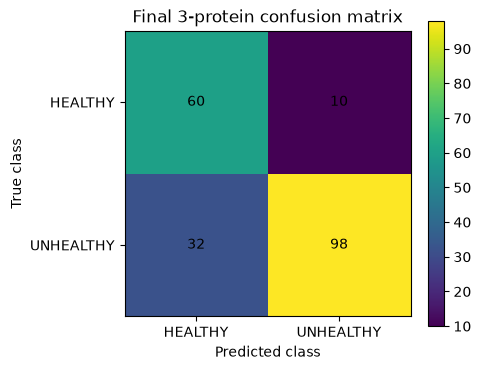

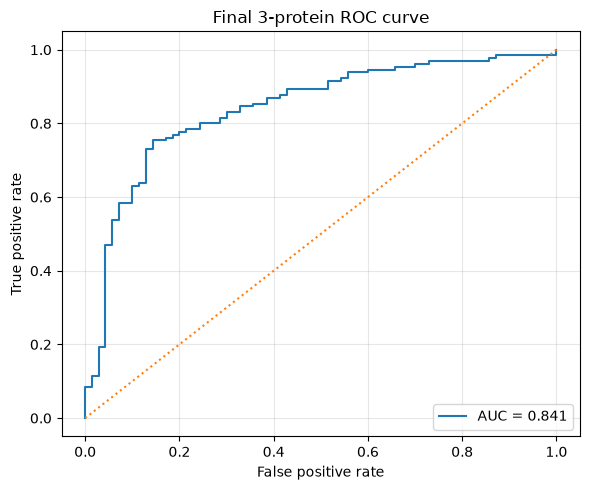

In [3]:
cm = np.array([[tn, fp], [fn, tp]])

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title("Final 3-protein confusion matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_xticks([0, 1], labels=["HEALTHY", "UNHEALTHY"])
ax.set_yticks([0, 1], labels=["HEALTHY", "UNHEALTHY"])

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")

fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, prob):.3f}")
plt.plot([0, 1], [0, 1], linestyle=":")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Final 3-protein ROC curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [4]:
predictions = test[["age", "cigarette_packs_year", "sex"]].copy()
predictions["Target"] = y_test
predictions["Prediction"] = pred

def binary_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
    }

def shared_interval_performance(data, variable, n_intervals=8):
    work = data[[variable, "Target", "Prediction"]].dropna().copy()
    work[variable] = pd.to_numeric(work[variable], errors="coerce")
    work = work.dropna(subset=[variable])

    healthy = work.loc[work["Target"] == 0, variable]
    unhealthy = work.loc[work["Target"] == 1, variable]

    low = max(healthy.min(), unhealthy.min())
    high = min(healthy.max(), unhealthy.max())
    overlap = work[work[variable].between(low, high)].copy()

    best = None

    for q_low in np.linspace(0.00, 0.35, 29):
        candidate_low = overlap[variable].quantile(q_low)

        for q_high in np.linspace(0.65, 1.00, 29):
            candidate_high = overlap[variable].quantile(q_high)

            if candidate_high <= candidate_low:
                continue

            edges = np.linspace(candidate_low, candidate_high, n_intervals + 1)
            candidate = overlap[
                overlap[variable].between(candidate_low, candidate_high)
            ].copy()

            candidate["Interval"] = pd.cut(
                candidate[variable],
                bins=edges,
                include_lowest=True,
            )

            valid = all(
                (group["Target"] == 0).sum() >= 1
                and (group["Target"] == 1).sum() >= 1
                for _, group in candidate.groupby("Interval", observed=False)
            )

            width = candidate_high - candidate_low

            if valid and (best is None or width > best["width"]):
                best = {"edges": edges, "width": width}

    if best is None:
        raise ValueError(f"Could not construct {n_intervals} shared intervals for {variable}.")

    work = overlap[
        overlap[variable].between(best["edges"][0], best["edges"][-1])
    ].copy()

    work["Interval"] = pd.cut(
        work[variable],
        bins=best["edges"],
        include_lowest=True,
    )

    rows = []

    for interval, group in work.groupby("Interval", observed=False):
        metrics = binary_metrics(group["Target"], group["Prediction"])
        rows.append({
            "Interval": str(interval),
            "X": (interval.left + interval.right) / 2,
            "N": len(group),
            **metrics,
        })

    return pd.DataFrame(rows)

def plot_metric(performance, metric, x_label, title):
    reg = linregress(performance["X"], performance[metric])
    x_line = np.linspace(performance["X"].min(), performance["X"].max(), 200)
    y_line = reg.intercept + reg.slope * x_line

    plt.figure(figsize=(8, 5))
    plt.scatter(performance["X"], performance[metric], s=60)
    plt.plot(
        x_line,
        y_line,
        label=f"Slope={reg.slope:.4f}, R²={reg.rvalue**2:.3f}, p={reg.pvalue:.4g}",
    )
    plt.ylim(0, 1.05)
    plt.xlabel(x_label)
    plt.ylabel(metric)
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return {
        "Metric": metric,
        "Slope": reg.slope,
        "R2": reg.rvalue ** 2,
        "P_value": reg.pvalue,
    }


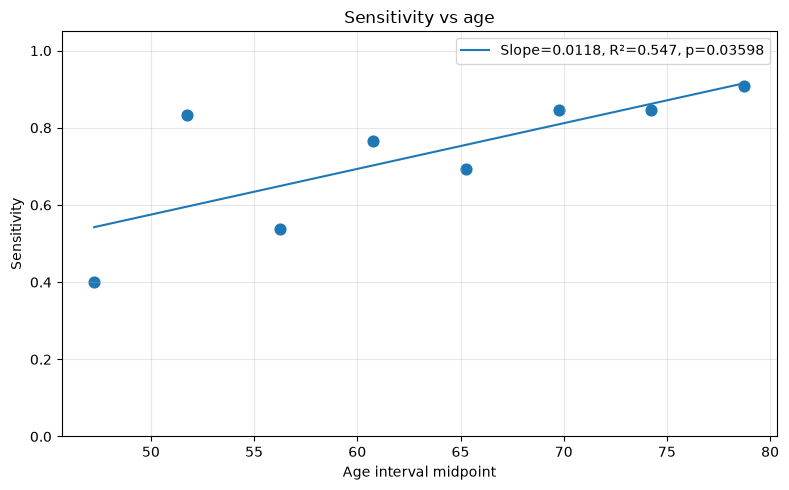

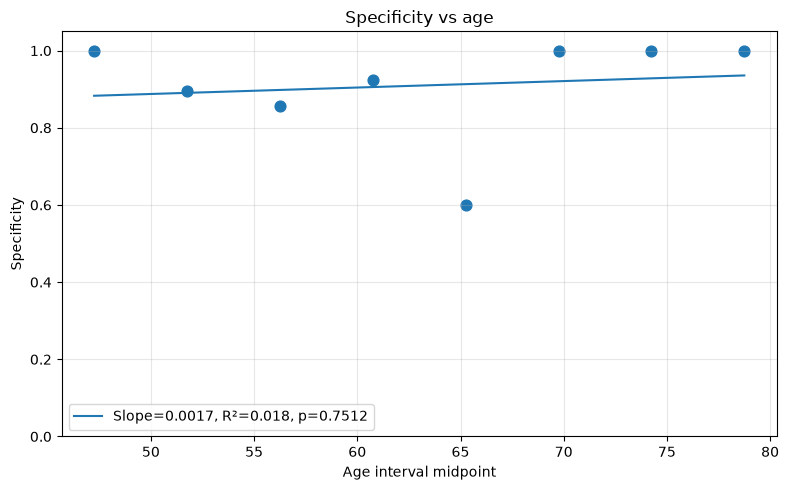

,Interval,X,N,Sensitivity,Specificity
0,"(44.999, 49.5]",47.2495,13,0.400000,1.000000
1,"(49.5, 54.0]",51.7500,25,0.833333,0.894737
2,"(54.0, 58.5]",56.2500,20,0.538462,0.857143
3,"(58.5, 63.0]",60.7500,43,0.766667,0.923077
4,"(63.0, 67.5]",65.2500,41,0.692308,0.600000
5,"(67.5, 72.0]",69.7500,30,0.846154,1.000000
6,"(72.0, 76.5]",74.2500,15,0.846154,1.000000
7,"(76.5, 81.0]",78.7500,12,0.909091,1.000000


In [5]:
AgePerformance = shared_interval_performance(predictions, "age", N_INTERVALS)

age_sensitivity = plot_metric(
    AgePerformance,
    "Sensitivity",
    "Age interval midpoint",
    "Sensitivity vs age",
)

age_specificity = plot_metric(
    AgePerformance,
    "Specificity",
    "Age interval midpoint",
    "Specificity vs age",
)

display(AgePerformance)


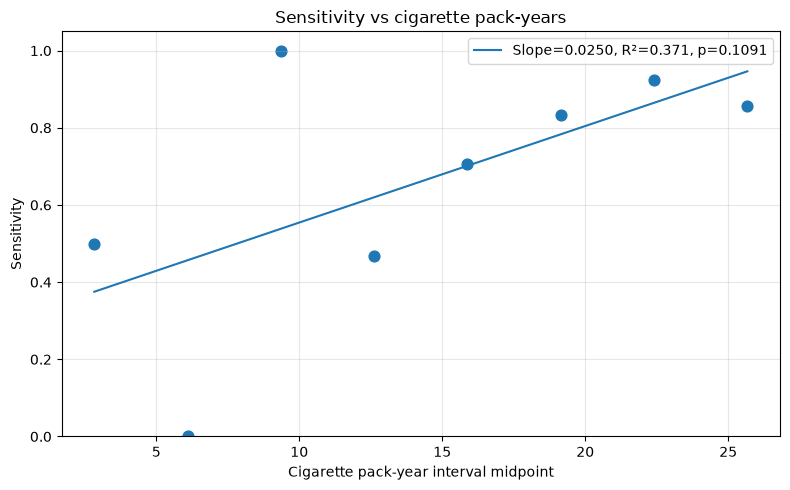

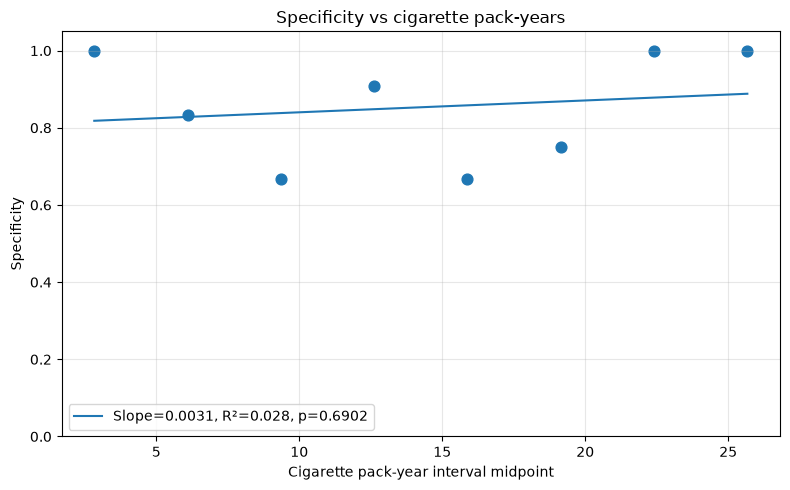

,Interval,X,N,Sensitivity,Specificity
0,"(1.199, 4.462]",2.8305,12,0.500000,1.000000
1,"(4.462, 7.725]",6.0935,16,0.000000,0.833333
2,"(7.725, 10.988]",9.3565,10,1.000000,0.666667
3,"(10.988, 14.25]",12.6190,26,0.466667,0.909091
4,"(14.25, 17.512]",15.8810,26,0.705882,0.666667
5,"(17.512, 20.775]",19.1435,22,0.833333,0.750000
6,"(20.775, 24.038]",22.4065,15,0.923077,1.000000
7,"(24.038, 27.3]",25.6690,22,0.857143,1.000000


In [6]:
SmokingPerformance = shared_interval_performance(
    predictions,
    "cigarette_packs_year",
    N_INTERVALS,
)

smoking_sensitivity = plot_metric(
    SmokingPerformance,
    "Sensitivity",
    "Cigarette pack-year interval midpoint",
    "Sensitivity vs cigarette pack-years",
)

smoking_specificity = plot_metric(
    SmokingPerformance,
    "Specificity",
    "Cigarette pack-year interval midpoint",
    "Specificity vs cigarette pack-years",
)

display(SmokingPerformance)


In [7]:
SexObserved = pd.DataFrame([
    {
        "Sex": label,
        **binary_metrics(
            predictions.loc[predictions["sex"] == value, "Target"],
            predictions.loc[predictions["sex"] == value, "Prediction"],
        ),
    }
    for value, label in [("H", "Male"), ("M", "Female")]
])

display(SexObserved)


,Sex,Sensitivity,Specificity
0,Male,0.750000,0.875000
1,Female,0.761905,0.842105


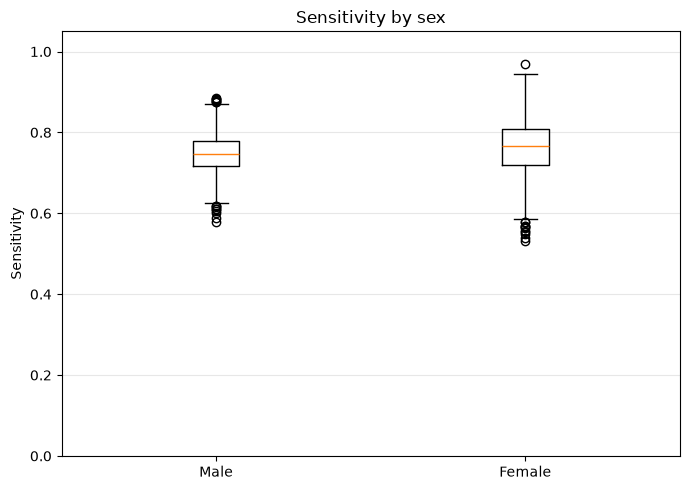

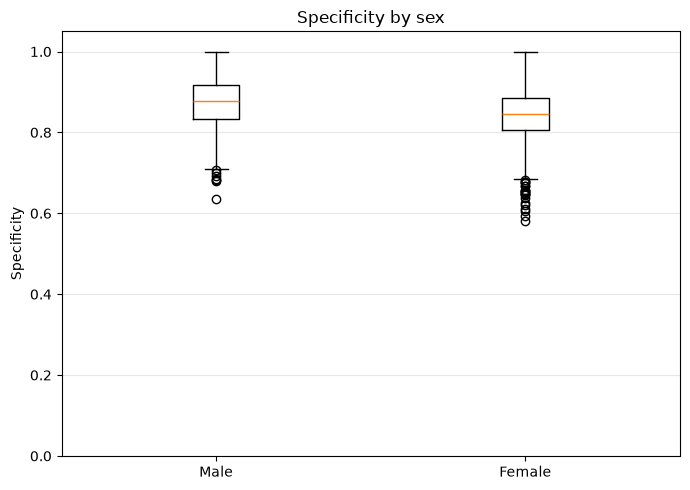

In [8]:
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_rows = []

for value, label in [("H", "Male"), ("M", "Female")]:
    group = predictions[predictions["sex"] == value].dropna(
        subset=["Target", "Prediction"]
    )

    for _ in range(N_BOOTSTRAP):
        sample = group.iloc[rng.integers(0, len(group), size=len(group))]
        bootstrap_rows.append({
            "Sex": label,
            **binary_metrics(sample["Target"], sample["Prediction"]),
        })

SexBootstrap = pd.DataFrame(bootstrap_rows)

for metric in ["Sensitivity", "Specificity"]:
    data = [
        SexBootstrap.loc[SexBootstrap["Sex"] == label, metric].dropna().to_numpy()
        for label in ["Male", "Female"]
    ]

    plt.figure(figsize=(7, 5))
    plt.boxplot(data, tick_labels=["Male", "Female"])
    plt.ylim(0, 1.05)
    plt.ylabel(metric)
    plt.title(f"{metric} by sex")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


In [9]:
TrendSummary = pd.DataFrame([
    {"Variable": "Age", **age_sensitivity},
    {"Variable": "Age", **age_specificity},
    {"Variable": "Cigarette pack-years", **smoking_sensitivity},
    {"Variable": "Cigarette pack-years", **smoking_specificity},
])

display(TrendSummary)


,Variable,Metric,Slope,R2,P_value
0,Age,Sensitivity,0.011842,0.546955,0.035985
1,Age,Specificity,0.001671,0.018041,0.751169
2,Cigarette pack-years,Sensitivity,0.025012,0.370732,0.109135
3,Cigarette pack-years,Specificity,0.003068,0.028360,0.690160


## Interpretation

The final model remains a **three-protein model** throughout this notebook. Age, smoking exposure and sex are used only to inspect how its errors and performance are distributed across subgroups.

Because some intervals contain small numbers of participants, these trends are exploratory and should not be interpreted as evidence of clinical generalizability.